# 01 — Comprensión del problema

En este notebook arrancamos el proyecto: miramos con qué datos vamos a trabajar (*TMDB 5000 Movie Dataset*), hacemos una primera exploración para entender cómo vienen y después planteamos el problema de negocio y las preguntas que nos van a guiar en el resto del trabajo.

## 1. Descripción del dataset

### 1.1 Contexto y fuente

Trabajamos con el **TMDB 5000 Movie Dataset**, publicado en Kaggle por la cuenta de TMDB ([enlace](https://www.kaggle.com/datasets/tmdb/tmdb-movie-metadata)). Tiene 4.803 películas estrenadas entre 1916 y 2017, y se armó con la API de TMDB (The Movie Database), una base de datos de cine que alimenta la misma comunidad de usuarios: ahí la gente sube el presupuesto, la recaudación, los géneros, las productoras, el reparto, etc.

**Tipo de fuente: secundaria.** Los datos no los recogimos nosotros: los registraron los usuarios de TMDB y después se exportaron y se subieron a Kaggle. Eso tiene una consecuencia directa: no sabemos con detalle cómo se llenó cada campo ni qué tan verificado está, y por eso más adelante nos vamos a encontrar campos vacíos y ceros que en realidad son datos que nadie reportó.

El dataset trae dos archivos, y los dos los dejamos en `data/raw/` comprimidos tal como vienen de Kaggle:

| Archivo | Qué tiene | Tamaño (zip / descomprimido) |
|---|---|---|
| `tmdb_5000_movies.csv` | La ficha de cada película en 20 columnas: presupuesto, recaudación, géneros, fecha, duración, idioma, votos, etc. | 1,7 MB / 5,7 MB |
| `tmdb_5000_credits.csv` | 4 columnas: la llave `movie_id`, el título y el reparto (`cast`) y equipo técnico (`crew`) de cada película | 7,7 MB / 40 MB |

Usamos los dos porque juntos nos dejan pensar como una productora que tiene que decidir en qué invertir: cuánto cuesta y cuánto deja una película, de qué género es, en qué idioma, cómo la calificó el público y quién la dirigió.

### 1.2 Carga de los datos

Leemos los dos archivos directamente desde los `.zip`: pandas los descomprime solo al leerlos, así que no hace falta tener los CSV sueltos en el repositorio (el de créditos pesa 40 MB descomprimido).

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 60)

RAW = Path("../data/raw")

In [2]:
movies = pd.read_csv(RAW / "tmdb_5000_movies.csv.zip")
credits = pd.read_csv(RAW / "tmdb_5000_credits.csv.zip")

for nombre, df in [("movies", movies), ("credits", credits)]:
    print(f"{nombre:8}: {df.shape[0]:,} filas x {df.shape[1]} columnas "
          f"({df.memory_usage(deep=True).sum() / 1e6:.1f} MB en memoria)")

movies  : 4,803 filas x 20 columnas (8.3 MB en memoria)
credits : 4,803 filas x 4 columnas (36.0 MB en memoria)


In [3]:
# ¿Las dos tablas describen las mismas películas? En movies la llave es `id` y en credits es `movie_id`
ids_movies = set(movies["id"])
ids_credits = set(credits["movie_id"])

print(f"Ids únicos en movies:  {len(ids_movies):,}")
print(f"Ids únicos en credits: {len(ids_credits):,}")
print(f"Ids en ambas tablas:   {len(ids_movies & ids_credits):,}")
print(f"Filas con id repetido en movies:  {movies['id'].duplicated().sum()}")
print(f"Filas con id repetido en credits: {credits['movie_id'].duplicated().sum()}")

titulos = movies.set_index("id")["title"]
titulos_credits = credits.set_index("movie_id")["title"].reindex(titulos.index)
print(f"Películas cuyo título no coincide entre las dos tablas: {(titulos != titulos_credits).sum()}")

Ids únicos en movies:  4,803
Ids únicos en credits: 4,803
Ids en ambas tablas:   4,803
Filas con id repetido en movies:  0
Filas con id repetido en credits: 0
Películas cuyo título no coincide entre las dos tablas: 0


**¿Qué vemos?** Las dos tablas tienen exactamente las mismas 4.803 películas, sin ningún `id` repetido y con el mismo título en ambas. O sea, la relación entre `movies` y `credits` es **uno a uno** y las podemos unir sin miedo a que se nos multipliquen filas. Lo único que hay que tener en cuenta es que la llave se llama distinto: `id` en películas y `movie_id` en créditos.

### 1.3 Exploración inicial

#### Primeras filas

In [4]:
movies.head(3)

,budget,genres,homepage,id,keywords,original_language,original_title,overview,popularity,production_companies,production_countries,release_date,revenue,runtime,spoken_languages,status,tagline,title,vote_average,vote_count
0,237000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""name"": ""Adven...",http://www.avatarmovie.com/,19995,"[{""id"": 1463, ""name"": ""culture clash""}, {""id"": 2964, ""na...",en,Avatar,"In the 22nd century, a paraplegic Marine is dispatched t...",150.437577,"[{""name"": ""Ingenious Film Partners"", ""id"": 289}, {""name""...","[{""iso_3166_1"": ""US"", ""name"": ""United States of America""...",2009-12-10,2787965087,162.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso_639_1"": ""...",Released,Enter the World of Pandora.,Avatar,7.2,11800
1,300000000,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""name"": ""Fa...",http://disney.go.com/disneypictures/pirates/,285,"[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""name"": ""drug...",en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, has come bac...",139.082615,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}, {""name"": ""Je...","[{""iso_3166_1"": ""US"", ""name"": ""United States of America""}]",2007-05-19,961000000,169.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"At the end of the world, the adventure begins.",Pirates of the Caribbean: At World's End,6.9,4500
2,245000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""name"": ""Adven...",http://www.sonypictures.com/movies/spectre/,206647,"[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name"": ""based ...",en,Spectre,A cryptic message from Bond’s past sends him on a trail ...,107.376788,"[{""name"": ""Columbia Pictures"", ""id"": 5}, {""name"": ""Danja...","[{""iso_3166_1"": ""GB"", ""name"": ""United Kingdom""}, {""iso_3...",2015-10-26,880674609,148.0,"[{""iso_639_1"": ""fr"", ""name"": ""Fran\u00e7ais""}, {""iso_639...",Released,A Plan No One Escapes,Spectre,6.3,4466


Lo primero que nos llamó la atención es que varias columnas no traen un dato sencillo sino **listas guardadas como texto**. Por ejemplo, `genres` de *Avatar* trae `[{"id": 28, "name": "Action"}, {"id": 12, "name": "Adventure"}, ...]`. O sea, una misma película puede tener varios géneros, varias productoras y varios países metidos en una sola celda. También hay columnas que no le aportan nada al análisis de negocio, como `homepage`, `overview` (la sinopsis) o `tagline` (la frase promocional).

#### Muestra aleatoria

In [5]:
cols_vista = ["title", "release_date", "budget", "revenue", "runtime",
              "original_language", "vote_average", "vote_count", "status"]
movies[cols_vista].sample(8, random_state=42)

,title,release_date,budget,revenue,runtime,original_language,vote_average,vote_count,status
596,I Spy,2002-10-31,70000000,33561137,97.0,en,5.2,269,Released
3372,Split Second,1992-05-01,7,5,90.0,en,5.7,63,Released
2702,Gossip,2000-04-21,14000000,5108820,90.0,en,5.5,68,Released
2473,Vicky Cristina Barcelona,2008-08-15,15000000,96408652,96.0,en,6.7,1020,Released
8,Harry Potter and the Half-Blood Prince,2009-07-07,250000000,933959197,153.0,en,7.4,5293,Released
577,AVP: Alien vs. Predator,2004-08-12,70000000,171183863,101.0,en,5.5,1217,Released
3172,The Contender,2000-10-13,9000000,0,126.0,en,6.7,60,Released
811,Meet the Parents,2000-10-06,55000000,330444045,108.0,en,6.6,1698,Released


Sacamos una muestra al azar porque las primeras filas son las superproducciones más caras (*Avatar*, *Piratas del Caribe*, *Spectre*) y no muestran cómo es el resto del dataset. En la muestra la mayoría de cifras se ven razonables, pero aparece *Split Second* con un presupuesto de **7** dólares y una recaudación de **5**: claramente alguien escribió las cifras en millones y no en dólares. Además de los ceros (que miramos en la sección 1.5), entonces también hay montos minúsculos que no son reales y que toca filtrar antes de calcular rentabilidad.

#### Tipos de dato

In [6]:
movies.info()

<class 'pandas.DataFrame'>
RangeIndex: 4803 entries, 0 to 4802
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   budget                4803 non-null   int64  
 1   genres                4803 non-null   str    
 2   homepage              1712 non-null   str    
 3   id                    4803 non-null   int64  
 4   keywords              4803 non-null   str    
 5   original_language     4803 non-null   str    
 6   original_title        4803 non-null   str    
 7   overview              4800 non-null   str    
 8   popularity            4803 non-null   float64
 9   production_companies  4803 non-null   str    
 10  production_countries  4803 non-null   str    
 11  release_date          4802 non-null   str    
 12  revenue               4803 non-null   int64  
 13  runtime               4801 non-null   float64
 14  spoken_languages      4803 non-null   str    
 15  status                4803 non-n

**¿Qué vemos?**

- Las variables numéricas se leyeron bien: `budget`, `revenue`, `id` y `vote_count` como enteros, y `popularity`, `runtime` y `vote_average` como decimales. No hay errores de tipo por filas dañadas.
- `release_date` está como texto; más adelante toca pasarla a fecha.
- Las columnas con listas (`genres`, `keywords`, `production_companies`, etc.) quedan como texto, porque pandas no sabe que adentro hay una lista.
- Hay pocos nulos explícitos: `homepage` (3.091), `tagline` (844), `overview` (3), `runtime` (2) y `release_date` (1). Pero que una columna no tenga nulos no quiere decir que esté completa: como vimos en la muestra, el problema de este dataset está en los ceros y en las listas vacías, no en los `NaN`.

#### Títulos repetidos

In [7]:
repetidos = movies[movies["title"].duplicated(keep=False)]
repetidos[["id", "title", "release_date", "original_language"]].sort_values("title")

,id,title,release_date,original_language
1359,268,Batman,1989-06-23,en
4267,2661,Batman,1966-07-30,en
3647,39269,Out of the Blue,1980-05-01,en
3693,10844,Out of the Blue,2006-10-12,en
972,72710,The Host,2013-03-22,en
2877,1255,The Host,2006-07-27,ko


Hay tres títulos que aparecen dos veces, pero con `id` y año distintos: son **películas diferentes con el mismo nombre** (el *Batman* de 1966 y el de 1989, por ejemplo), no registros duplicados. Por eso, para identificar una película siempre usamos el `id` y no el título.

#### Estadística descriptiva

In [8]:
movies.describe().T

,count,mean,std,min,25%,50%,75%,max
budget,4803.0,2.904504e+07,4.072239e+07,0.0,790000.00000,1.500000e+07,4.000000e+07,3.800000e+08
id,4803.0,5.716548e+04,8.869461e+04,5.0,9014.50000,1.462900e+04,5.861050e+04,4.594880e+05
popularity,4803.0,2.149230e+01,3.181665e+01,0.0,4.66807,1.292159e+01,2.831350e+01,8.755813e+02
revenue,4803.0,8.226064e+07,1.628571e+08,0.0,0.00000,1.917000e+07,9.291719e+07,2.787965e+09
runtime,4801.0,1.068759e+02,2.261193e+01,0.0,94.00000,1.030000e+02,1.180000e+02,3.380000e+02
vote_average,4803.0,6.092172e+00,1.194612e+00,0.0,5.60000,6.200000e+00,6.800000e+00,1.000000e+01
vote_count,4803.0,6.902180e+02,1.234586e+03,0.0,54.00000,2.350000e+02,7.370000e+02,1.375200e+04


**¿Qué vemos?**

- `budget`: la mediana es de 15 millones de dólares, pero la media sube a 29 millones porque unas pocas superproducciones (hasta 380 millones) jalan el promedio. El mínimo es 0 y el percentil 25 es apenas 790.000 dólares, una primera señal de que hay muchos ceros.
- `revenue`: el percentil 25 ya es 0, o sea que por lo menos una de cada cuatro películas no tiene recaudación reportada. La media (82 millones) es más de cuatro veces la mediana (19 millones) y el máximo llega a 2.788 millones (*Avatar*): una distribución supremamente sesgada a la derecha, donde unas pocas taquilleras se llevan casi toda la plata.
- `runtime`: hay películas que "duran" 0 minutos (dato no reportado) y una de 338 minutos (*Carlos*, que en realidad es una miniserie de TV). Toca revisar esos extremos en el diagnóstico de calidad.
- `vote_average`: va de 0 a 10, que es la escala de TMDB, con la mitad de las películas entre 5,6 y 6,8.
- `vote_count`: la mediana es de 235 votos y la media de 690. La mayoría de películas tiene pocos votos y unas cuantas tienen miles (el máximo es 13.752).

In [9]:
movies.describe(exclude="number").T[["count", "unique", "top", "freq"]]

,count,unique,top,freq
genres,4803,1175,"[{""id"": 18, ""name"": ""Drama""}]",370
homepage,1712,1691,http://www.thehungergames.movie/,4
keywords,4803,4222,[],412
original_language,4803,37,en,4505
original_title,4803,4801,Batman,2
overview,4800,4800,"In the 22nd century, a paraplegic Marine is dispatched t...",1
production_companies,4803,3697,[],351
production_countries,4803,469,"[{""iso_3166_1"": ""US"", ""name"": ""United States of America""}]",2977
release_date,4802,3280,2006-01-01,10
spoken_languages,4803,544,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",3171


En las columnas de texto:

- `status` solo tiene 3 valores y casi todas las películas están `Released`.
- Hay 37 idiomas originales, pero el inglés (`en`) domina por mucho.
- En `keywords` y `production_companies` el valor más frecuente es `[]`, una **lista vacía**: es otra forma de faltante disfrazado, porque no hay un `NaN` pero tampoco hay dato. En `genres` el valor más común es solo `Drama`.
- `title` tiene 4.800 valores únicos para 4.803 filas, que son justamente los tres títulos repetidos que ya revisamos.

#### Archivo de créditos

In [10]:
credits.info()
print()
print("Películas sin reparto (cast vacío):        ", (credits["cast"] == "[]").sum())
print("Películas sin equipo técnico (crew vacío): ", (credits["crew"] == "[]").sum())
credits.head(2)

<class 'pandas.DataFrame'>
RangeIndex: 4803 entries, 0 to 4802
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   movie_id  4803 non-null   int64
 1   title     4803 non-null   str  
 2   cast      4803 non-null   str  
 3   crew      4803 non-null   str  
dtypes: int64(1), str(3)
memory usage: 150.2 KB

Películas sin reparto (cast vacío):         43
Películas sin equipo técnico (crew vacío):  28


,movie_id,title,cast,crew
0,19995,Avatar,"[{""cast_id"": 242, ""character"": ""Jake Sully"", ""credit_id""...","[{""credit_id"": ""52fe48009251416c750aca23"", ""department"":..."
1,285,Pirates of the Caribbean: At World's End,"[{""cast_id"": 4, ""character"": ""Captain Jack Sparrow"", ""cr...","[{""credit_id"": ""52fe4232c3a36847f800b579"", ""department"":..."


`credits` tiene cuatro columnas: `movie_id`, `title`, `cast` y `crew`. `cast` y `crew` también son listas guardadas como texto, con un elemento por persona, y no tienen nulos, aunque hay 43 películas con el reparto vacío y 28 con el equipo técnico vacío. En `crew` cada persona tiene su cargo (`job`), por ejemplo `Director`, `Producer` o `Screenplay`, y de ahí podemos sacar el director de cada película, que es la variable de talento que vamos a usar en el modelo.

### 1.4 Clasificación de variables

**`tmdb_5000_movies.csv`**

| Variable | Qué es | Tipo | Subtipo | Cómo viene en el archivo |
|---|---|---|---|---|
| `budget` | Presupuesto (USD) | Cuantitativa | Continua | Entero |
| `genres` | Géneros | Cualitativa | Nominal con varios valores | Lista JSON como texto |
| `homepage` | Página web oficial | Cualitativa | Nominal (texto libre) | Texto |
| `id` | Código de TMDB | Identificador | No aplica | Entero |
| `keywords` | Palabras clave de la trama | Cualitativa | Nominal con varios valores | Lista JSON como texto |
| `original_language` | Idioma original (código ISO 639-1) | Cualitativa | Nominal | Texto |
| `original_title` | Título original | Cualitativa | Nominal (texto libre) | Texto |
| `overview` | Sinopsis | Cualitativa | Texto libre | Texto |
| `popularity` | Índice de popularidad de TMDB | Cuantitativa | Continua | Decimal |
| `production_companies` | Productoras | Cualitativa | Nominal con varios valores | Lista JSON como texto |
| `production_countries` | Países de producción | Cualitativa | Nominal con varios valores | Lista JSON como texto |
| `release_date` | Fecha de estreno | Temporal | Fecha (de ahí salen año y mes, que son discretas) | Texto |
| `revenue` | Recaudación (USD) | Cuantitativa | Continua | Entero |
| `runtime` | Duración (minutos) | Cuantitativa | Continua | Decimal |
| `spoken_languages` | Idiomas que se hablan en la película | Cualitativa | Nominal con varios valores | Lista JSON como texto |
| `status` | Estado (Released, Rumored, Post Production) | Cualitativa | Ordinal (etapas de la producción) | Texto |
| `tagline` | Frase promocional | Cualitativa | Texto libre | Texto |
| `title` | Título | Cualitativa | Nominal (texto libre) | Texto |
| `vote_average` | Calificación promedio (0 a 10) | Cuantitativa | Continua | Decimal |
| `vote_count` | Número de votos | Cuantitativa | Discreta | Entero |

**`tmdb_5000_credits.csv`**

| Variable | Qué es | Tipo | Subtipo | Cómo viene |
|---|---|---|---|---|
| `movie_id` | Código de TMDB (la llave para unir con `id` de películas) | Identificador | No aplica | Entero |
| `title` | Título (igual al de la tabla de películas) | Cualitativa | Nominal (texto libre) | Texto |
| `cast` | Reparto (actor, personaje, orden) | Cualitativa | Nominal con varios valores | Lista JSON como texto |
| `crew` | Equipo técnico (nombre, departamento, cargo) | Cualitativa | Nominal con varios valores | Lista JSON como texto |

Algo que notamos al clasificar: en los datos crudos casi no hay variables ordinales. La única que tiene un orden natural es `status`, porque sus valores siguen la vida de una película (rumor → postproducción → estrenada). Más adelante vamos a crear variables ordinales propias, como la categoría de duración.

Para no quedarnos solo con lo que vimos a ojo, comprobamos con código cuáles columnas vienen como listas y si de verdad son JSON:

In [11]:
def es_anidada(serie):
    # Una columna es anidada si casi todos sus valores no nulos empiezan como lista o diccionario
    muestra = serie.dropna().astype(str).head(500)
    return len(muestra) > 0 and muestra.str.startswith(("[", "{")).mean() > 0.9

anidadas_movies = [c for c in movies.columns if es_anidada(movies[c])]
anidadas_credits = [c for c in credits.columns if es_anidada(credits[c])]
print("Columnas anidadas en movies: ", anidadas_movies)
print("Columnas anidadas en credits:", anidadas_credits)

Columnas anidadas en movies:  ['genres', 'keywords', 'production_companies', 'production_countries', 'spoken_languages']
Columnas anidadas en credits: ['cast', 'crew']


In [12]:
def falla_json(texto):
    try:
        json.loads(texto)
        return False
    except json.JSONDecodeError:
        return True

for df, columnas in [(movies, anidadas_movies), (credits, anidadas_credits)]:
    for col in columnas:
        print(f"{col:22} filas que json.loads no puede leer: {df[col].apply(falla_json).sum()}")

print()
print("Ejemplo convertido:", [g["name"] for g in json.loads(movies.loc[0, "genres"])])

genres                 filas que json.loads no puede leer: 0
keywords               filas que json.loads no puede leer: 0
production_companies   filas que json.loads no puede leer: 0
production_countries   filas que json.loads no puede leer: 0
spoken_languages       filas que json.loads no puede leer: 0


cast                   filas que json.loads no puede leer: 0


crew                   filas que json.loads no puede leer: 0

Ejemplo convertido: ['Action', 'Adventure', 'Fantasy', 'Science Fiction']


**¿Qué vemos?** Las siete columnas anidadas son **JSON válido** (usan comillas dobles) y `json.loads` las lee todas sin un solo error, así que en la limpieza basta con `json.loads` para convertirlas en listas de nombres.

Además, las columnas con varios valores (`genres`, `production_companies`, `production_countries`, `spoken_languages`) generan una relación **muchos a muchos**: una película tiene varios géneros y un género tiene muchas películas. Cuando armemos el modelo dimensional, eso nos obliga a usar una tabla puente.

### 1.5 Primeras observaciones

#### ¿Qué periodo cubre el dataset?

Fecha mínima: 1916-09-04
Fecha máxima: 2017-02-03
Fechas vacías o inválidas: 1
Películas estrenadas desde 1990: 88.9%
Año con más estrenos: 2009
Estrenos de los últimos años: {2014.0: 238, 2015.0: 216, 2016.0: 104, 2017.0: 1}


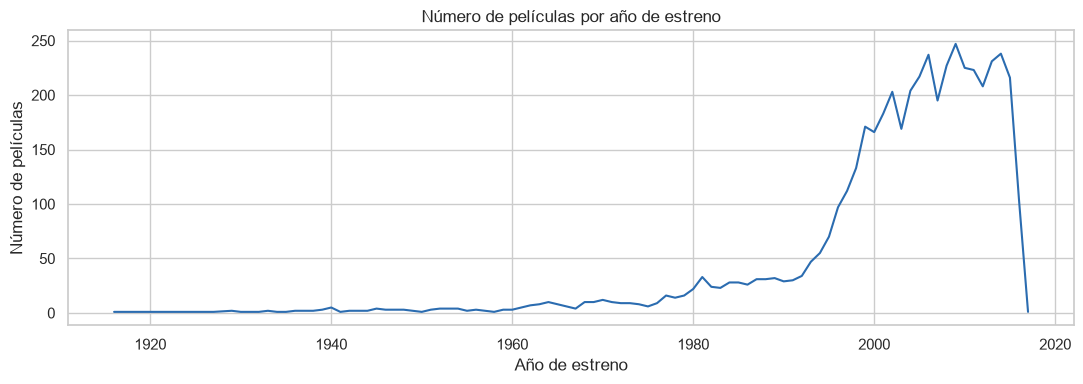

In [13]:
fechas = pd.to_datetime(movies["release_date"], errors="coerce")
anios = fechas.dt.year

print(f"Fecha mínima: {fechas.min().date()}")
print(f"Fecha máxima: {fechas.max().date()}")
print(f"Fechas vacías o inválidas: {fechas.isna().sum()}")
print(f"Películas estrenadas desde 1990: {(anios >= 1990).mean():.1%}")
print(f"Año con más estrenos: {int(anios.mode()[0])}")
print("Estrenos de los últimos años:", anios.value_counts().sort_index().tail(4).astype(int).to_dict())

fig, ax = plt.subplots(figsize=(11, 4))
anios.dropna().astype(int).value_counts().sort_index().plot(ax=ax, color="#2b6cb0")
ax.set_title("Número de películas por año de estreno")
ax.set_xlabel("Año de estreno")
ax.set_ylabel("Número de películas")
plt.tight_layout()
plt.show()

**¿Qué vemos?** El dataset va de 1916 a febrero de 2017, pero casi todas las películas son recientes: el 89 % se estrenó desde 1990 y el año con más películas es 2009. En parte es porque cada vez se hacen más películas, y en parte porque TMDB es una comunidad relativamente nueva que tiene mejor registrado el cine reciente. La caída del final no quiere decir que se hayan hecho menos películas: 2016 tiene más o menos la mitad de estrenos que 2015 y de 2017 solo hay una, porque los datos se sacaron a principios de 2017 y esos años quedaron incompletos.

Para la productora esto significa que hay que tener cuidado al comparar décadas, y que el periodo más confiable para tomar decisiones son las décadas recientes.

#### Ceros en presupuesto, recaudación y duración

,ceros,nulos,% ceros
budget,1037,0,21.6
revenue,1427,0,29.7
runtime,35,2,0.7


Películas con presupuesto Y recaudación reportados: 3,229 (67.2% del total)


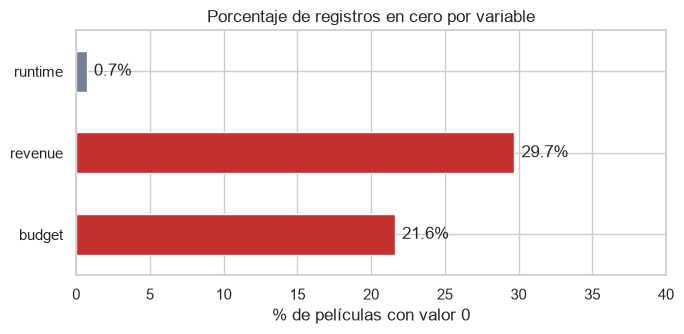

In [14]:
financieras = movies[["budget", "revenue", "runtime"]]

resumen_ceros = pd.DataFrame({
    "ceros": (financieras == 0).sum(),
    "nulos": financieras.isna().sum(),
})
resumen_ceros["% ceros"] = (resumen_ceros["ceros"] / len(movies) * 100).round(1)
display(resumen_ceros)

con_ambos = ((financieras["budget"] > 0) & (financieras["revenue"] > 0)).sum()
print(f"Películas con presupuesto Y recaudación reportados: {con_ambos:,} "
      f"({con_ambos / len(movies):.1%} del total)")

fig, ax = plt.subplots(figsize=(7, 3.5))
resumen_ceros["% ceros"].plot.barh(ax=ax, color=["#c53030", "#c53030", "#718096"])
ax.set_title("Porcentaje de registros en cero por variable")
ax.set_xlabel("% de películas con valor 0")
ax.set_ylabel("")
for i, v in enumerate(resumen_ceros["% ceros"]):
    ax.text(v + 0.5, i, f"{v}%", va="center")
ax.set_xlim(0, 40)
plt.tight_layout()
plt.show()

**¿Qué vemos?** Esta es, para nosotros, la observación más importante de esta primera parte. El **21,6 % de las películas tiene el presupuesto en 0** (1.037) y el **29,7 % tiene la recaudación en 0** (1.427). No es que sean películas gratis o que no hayan vendido nada: son **faltantes disfrazados**, datos que nadie subió a TMDB. Si los tomáramos como ceros reales, el ROI y la ganancia promedio quedarían totalmente distorsionados.

Las películas que tienen presupuesto y recaudación reportados son 3.229, el 67,2 % del total. Ese grupo es la base real de cualquier análisis financiero que hagamos, y no es una muestra al azar: las cifras de taquilla se reportan sobre todo en producciones grandes y comerciales. Entonces, lo que concluyamos sobre rentabilidad aplica a ese tipo de películas y no a todo el cine. Lo dejamos anotado desde ya como una limitación del estudio.

En `runtime` los ceros son pocos (35, más 2 nulos), así que se pueden manejar como faltantes sin que afecten el análisis.

#### Estado de las películas e idioma original

In [15]:
print("Estado (status):")
display(movies["status"].value_counts(dropna=False).to_frame("películas"))

print("Top 10 idiomas originales (% de películas):")
display((movies["original_language"].value_counts(normalize=True).head(10) * 100)
        .round(1).to_frame("% películas"))

Estado (status):


,películas
status,
Released,4795
Rumored,5
Post Production,3


Top 10 idiomas originales (% de películas):


,% películas
original_language,
en,93.8
fr,1.5
es,0.7
zh,0.6
de,0.6
hi,0.4
ja,0.3
it,0.3
cn,0.2


**¿Qué vemos?** 4.795 de las 4.803 películas ya están estrenadas (`Released`). Las 8 restantes (5 en rumor y 3 en postproducción) no tienen taquilla ni calificación real, así que no sirven para medir desempeño y toca sacarlas del análisis.

El inglés es el idioma original del 93,8 % de las películas; el que le sigue, el francés, no llega ni al 2 %. El dataset está cargado hacia el cine en inglés (sobre todo de Estados Unidos), lo cual tiene lógica porque viene de una comunidad principalmente anglosajona. Cuando comparemos por idioma, los grupos diferentes al inglés van a ser muy pequeños y hay que leer esos resultados con cuidado.

#### Cantidad de votos

In [16]:
votos = movies["vote_count"]
print(f"Mediana de votos por película: {votos.median():.0f}")
print(f"Media de votos por película:   {votos.mean():.0f}")
print(f"Películas sin ningún voto:       {(votos == 0).sum()}")
print(f"Películas con menos de 10 votos: {(votos < 10).mean():.1%}")
print(f"Películas con 1.000 votos o más: {(votos >= 1000).mean():.1%}")

movies.loc[movies["vote_average"] >= 9, ["title", "vote_average", "vote_count"]]

Mediana de votos por película: 235
Media de votos por película:   690
Películas sin ningún voto:       62
Películas con menos de 10 votos: 8.6%
Películas con 1.000 votos o más: 19.2%


,title,vote_average,vote_count
2386,One Man's Hero,9.3,2
3519,Stiff Upper Lips,10.0,1
3992,Sardaarji,9.5,2
4045,"Dancer, Texas Pop. 81",10.0,1
4247,Me You and Five Bucks,10.0,2
4662,Little Big Top,10.0,1


**¿Qué vemos?** La mitad de las películas tiene 235 votos o menos, 62 no tienen ni un voto y apenas el 19 % pasa de mil. Las seis películas con calificación de 9 o más tienen apenas uno o dos votos. Un 10 con un voto no se puede comparar con un 7,5 con diez mil votos. Por eso, cuando usemos la calificación como indicador, no podemos promediar `vote_average` así no más: vamos a necesitar un mínimo de votos o una calificación ponderada por la cantidad de votos.

### 1.6 Lo que nos llevamos de esta exploración

1. El dataset es manejable y está bien armado. Son 4.803 películas en dos tablas que se cruzan uno a uno por el `id` de TMDB, sin duplicados ni errores de tipo.
2. Hay faltantes disfrazados. El 21,6 % de los presupuestos y el 29,7 % de las recaudaciones están en 0, y también hay montos absurdos (como un presupuesto de 7 dólares) y listas vacías en géneros, productoras y créditos. El análisis de rentabilidad lo vamos a hacer sobre las 3.229 películas que reportan las dos cifras, y vamos a dejar claro que son sobre todo producciones comerciales.
3. Géneros, productoras, países, reparto y equipo técnico vienen como listas JSON guardadas en texto. Se leen con `json.loads` y, por la relación muchos a muchos, el género va a necesitar una tabla puente en el modelo.
4. Hay sesgos que cambian cómo leemos los resultados: predomina el cine en inglés (93,8 %), la mayoría de películas son de 1990 en adelante, 2016 y 2017 están incompletos y las calificaciones con pocos votos no son confiables.

Con todo esto claro, pasamos a definir el problema de negocio y las preguntas clave.

## 2. Problema de negocio y preguntas clave

### 2.1 El problema

Nos ponemos en los zapatos de una productora independiente que tiene un capital limitado para financiar películas en los próximos años. Cada película es una apuesta: la plata se invierte mucho antes del estreno, sin saber si al público le va a gustar, y una película que fracase se puede comer la ganancia de varias que salieron bien.

La pregunta de fondo es **en qué películas conviene invertir para aumentar la probabilidad de recuperar la plata con ganancia**. La productora tiene tres palancas para eso: cuánto invertir en cada película, cuándo estrenarla y qué tipo de película hacer. El TMDB 5000 nos sirve porque tiene, para miles de películas ya estrenadas, cuánto costaron, cuánto recaudaron, su género y su fecha de estreno; o sea, el historial de qué ha funcionado y qué no.

Antes de plantear las preguntas medimos qué tan riesgoso es el negocio. Usamos solo las películas estrenadas que reportaron presupuesto y recaudación, y dejamos por fuera las que tienen algún monto menor a 10.000 dólares, que casi siempre son errores de digitación (presupuestos de 1 o 25 dólares, por ejemplo; en el diagnóstico del notebook 02 están una por una).

In [17]:
from matplotlib.ticker import FuncFormatter

MONTO_MINIMO = 10_000
UMBRAL_RENTABLE = 2
AZUL, ROJO, GRIS = "#2b6cb0", "#c53030", "#a0aec0"
MESES = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

estrenadas = movies[movies["status"] == "Released"]
finanzas = estrenadas[(estrenadas["budget"] >= MONTO_MINIMO)
                      & (estrenadas["revenue"] >= MONTO_MINIMO)].copy()
finanzas["multiplicador"] = finanzas["revenue"] / finanzas["budget"]

recaudacion = finanzas["revenue"].sort_values(ascending=False)
top_10 = recaudacion.head(len(recaudacion) // 10)

print(f"Películas con presupuesto y recaudación: {len(finanzas):,}")
print(f"Multiplicador mediano (recaudación / presupuesto): {finanzas['multiplicador'].median():.2f}")
print(f"El 10 % más taquillero ({len(top_10)} películas) se lleva el "
      f"{top_10.sum() / recaudacion.sum():.1%} de la recaudación total")

Películas con presupuesto y recaudación: 3,204
Multiplicador mediano (recaudación / presupuesto): 2.31
El 10 % más taquillero (320 películas) se lleva el 46.5% de la recaudación total


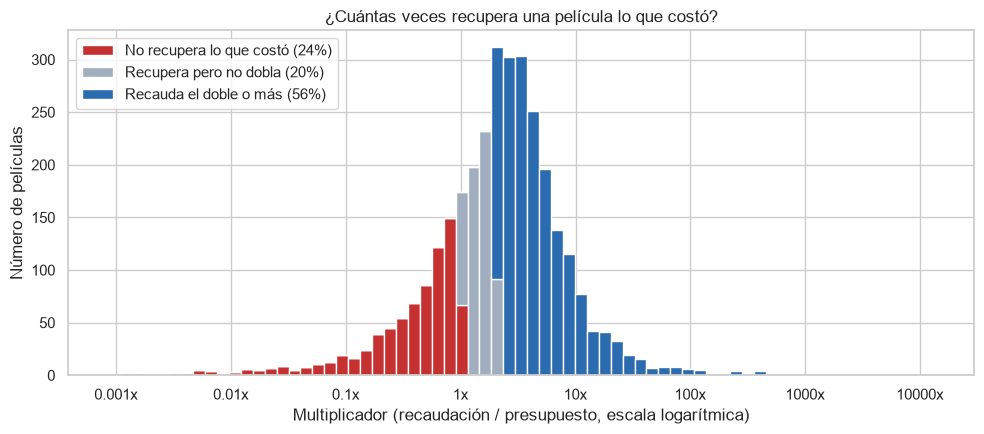

In [18]:
zona = pd.cut(finanzas["multiplicador"], [0, 1, UMBRAL_RENTABLE, np.inf], right=False,
              labels=["No recupera lo que costó", "Recupera pero no dobla", "Recauda el doble o más"])
porcentajes = zona.value_counts(normalize=True)
bordes = np.logspace(np.log10(finanzas["multiplicador"].min()),
                     np.log10(finanzas["multiplicador"].max()), 70)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist([finanzas.loc[zona == nombre, "multiplicador"] for nombre in zona.cat.categories],
        bins=bordes, stacked=True, color=[ROJO, GRIS, AZUL],
        label=[f"{nombre} ({porcentajes[nombre]:.0%})" for nombre in zona.cat.categories])
ax.set_xscale("log")
ax.xaxis.set_major_formatter(FuncFormatter(lambda valor, _: f"{valor:g}x"))
ax.set_title("¿Cuántas veces recupera una película lo que costó?")
ax.set_xlabel("Multiplicador (recaudación / presupuesto, escala logarítmica)")
ax.set_ylabel("Número de películas")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

**¿Qué vemos?** El multiplicador mediano es de 2,3, pero la dispersión es enorme: hay películas que no recaudaron ni la milésima parte de lo que costaron y otras que recaudaron más de diez mil veces su presupuesto. Una de cada cuatro no recuperó ni lo que costó, y si pedimos recaudar el doble, que es más o menos lo que se necesita para cubrir lo que se quedan las salas y la publicidad (el criterio lo explicamos en el notebook 03), el 44 % se queda corto.

Además, la plata está muy concentrada: el 10 % de películas más taquilleras se lleva casi la mitad de toda la recaudación. El negocio depende de pocos éxitos grandes, y por eso escoger bien en qué invertir pesa tanto.

### 2.2 Preguntas clave

Con ese panorama, partimos la decisión de inversión en tres preguntas, una por cada palanca que controla la productora. Las tres se pueden responder con el dataset y se van a poder seguir en el dashboard.

#### Pregunta 1. ¿Meterle más presupuesto a una película hace que rinda más por cada dólar invertido?

Es la primera decisión: cuánto poner. Una película más cara puede tener mejores actores, más efectos y más publicidad, pero también necesita recaudar mucho más para salir tablas. Con la concentración que acabamos de ver, la tentación es buscar el próximo gran éxito metiéndole más plata. Si el retorno no mejora con el presupuesto, a una productora con capital limitado le conviene más repartir la inversión en varias películas que apostarla toda a una grande.

#### Pregunta 2. ¿Estrenar en temporada alta mejora el retorno de una película?

Es de las pocas decisiones que todavía se pueden tomar cuando la película ya está hecha. Primero miramos cómo reparten los estudios sus estrenos durante el año:

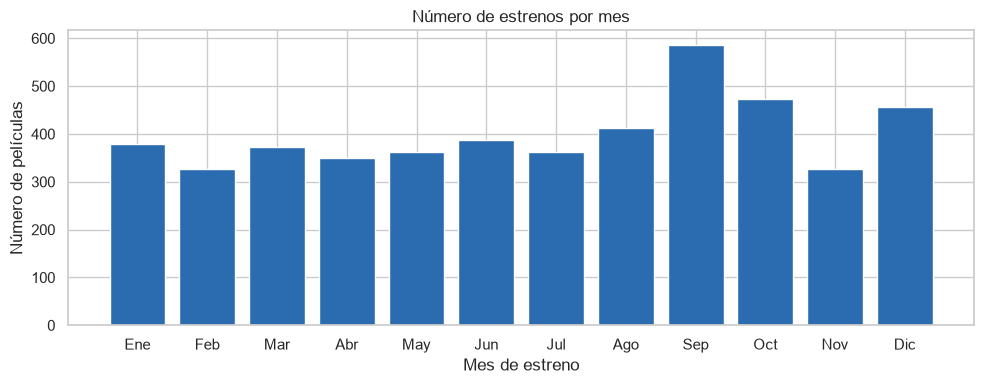

,Ene,Feb,Mar,Abr,May,Jun,Jul,Ago,Sep,Oct,Nov,Dic
estrenos,380,326,372,349,363,388,362,412,587,473,326,456


In [19]:
estrenos_por_mes = (pd.to_datetime(estrenadas["release_date"], errors="coerce")
                    .dt.month.value_counts().sort_index())

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar([MESES[int(mes) - 1] for mes in estrenos_por_mes.index], estrenos_por_mes, color=AZUL)
ax.set_title("Número de estrenos por mes")
ax.set_xlabel("Mes de estreno")
ax.set_ylabel("Número de películas")
plt.tight_layout()
plt.show()

estrenos_por_mes.rename(index=lambda mes: MESES[int(mes) - 1]).rename_axis(None).to_frame("estrenos").T

**¿Qué vemos?** Los estrenos no se reparten parejo. Septiembre es el mes con más estrenos (587), seguido de octubre y diciembre, mientras que febrero y noviembre son los que menos tienen (326 cada uno). En septiembre son festivales como los de Venecia y Toronto, y TMDB suele guardar la primera fecha en que se proyectó la película, así que es posible que parte de ese pico sean estrenos en festivales y no comerciales.

Para la pregunta, lo importante es que en los meses llenos de estrenos hay más competencia por las salas y por el público. Entonces no es obvio si conviene estrenar en las fechas en que más gente va a cine, como las vacaciones de mitad y de fin de año, o buscar meses con menos competencia.

#### Pregunta 3. ¿El género influye en la probabilidad de que una película sea rentable?

Es la decisión de qué tipo de película hacer: define el guion, el reparto y el público. Miramos cuáles géneros son los que más se producen:

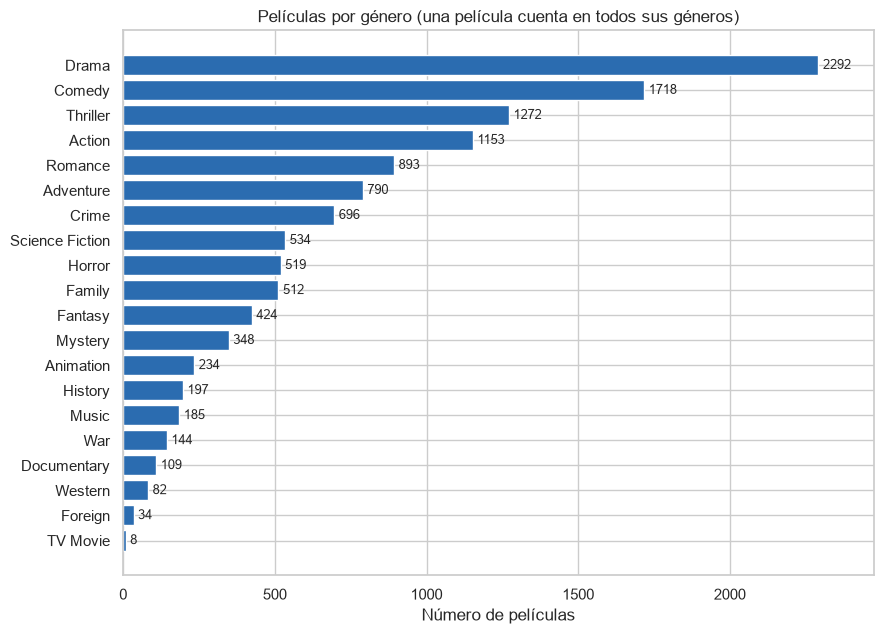

Películas con más de un género: 80.7%


In [20]:
generos = estrenadas["genres"].apply(lambda texto: [g["name"] for g in json.loads(texto)])
peliculas_por_genero = generos.explode().value_counts().sort_values()

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(peliculas_por_genero.index, peliculas_por_genero, color=AZUL)
for i, cantidad in enumerate(peliculas_por_genero):
    ax.text(cantidad + 15, i, f"{cantidad}", va="center", fontsize=9)
ax.set_xlim(0, peliculas_por_genero.max() * 1.08)
ax.set_title("Películas por género (una película cuenta en todos sus géneros)")
ax.set_xlabel("Número de películas")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

print(f"Películas con más de un género: {(generos.str.len() > 1).mean():.1%}")

**¿Qué vemos?** Drama y comedia dominan por mucho, seguidos de thriller y acción. Como el 81 % de las películas tiene más de un género, la suma de las barras da bastante más que el total de películas; por eso, como dijimos en la sección 1.4, el género necesita una tabla puente en el modelo de datos.

Hay mucha más oferta en unos géneros que en otros, y la pregunta es si lo que más se produce es también lo que más rinde, o si hay géneros menos explotados con mejor probabilidad de ser rentables.

### 2.3 Resumen

| Pregunta clave | Decisión que apoya | Cómo la vamos a responder |
|---|---|---|
| 1. ¿Meterle más presupuesto a una película hace que rinda más por cada dólar invertido? | Cuánto invertir en cada película | Hipótesis 1 del notebook 03 (correlación de Spearman entre presupuesto y multiplicador) y comparación del retorno por rango de presupuesto en el dashboard |
| 2. ¿Estrenar en temporada alta mejora el retorno de una película? | Cuándo estrenar | Hipótesis 2 (t de Student entre temporada alta y resto del año) y el retorno por mes de estreno en el dashboard |
| 3. ¿El género influye en la probabilidad de que una película sea rentable? | Qué tipo de película hacer | Hipótesis 3 (chi-cuadrado entre género y ser rentable) y el desempeño por género en el dashboard |

Las tres preguntas se miden con la misma vara: el **multiplicador** (recaudación / presupuesto) y si la película es **rentable**, es decir, si recaudó al menos el doble de lo que costó. Lo que concluyamos aplica a películas comerciales que reportaron sus cifras, la gran mayoría en inglés, y eso lo vamos a tener presente en todo el análisis.